In [1]:
import fastf1
import matplotlib.pyplot as plt
from fastf1 import utils
import numpy as np
import scipy as sp
import pandas as pd
import seaborn as sns

In [2]:
fastf1.Cache.clear_cache('fastf1_cache')
fastf1.Cache.enable_cache('fastf1_cache')

In [3]:
#specify the session and call the session
year= 2026
race = 'Singapore'
session = 'race'
session_data = fastf1.get_session(year, race, session)
session_data.load()
laps = session_data.laps

core           INFO 	Loading data for Singapore Grand Prix - Race [v3.0.2]
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
logger      WARNING 	Failed to load result data from Ergast!
core        WARNING 	No result data for this session available on Ergast! (This is expected for recent sessions)
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached

In [4]:
drivers = ['VER', 'ANT', 'LEC', "HAM", 'RUS', 'NOR', 
           'PIA','LAW', 'HUL', 'HAD', 'GAS', 'BEA', 
           'OCO', "SAI", 'LIN', 'ALO', 'PER', 'ALB',
           'BOT', 'STR', 'COL', 'BOR']  # Specify the drivers you want to analyze
car_data = {}

#specify the drivers and getting the fastest laps
for i in drivers:
    car_data[i] = laps.pick_driver(i).pick_fastest().get_car_data().add_distance()
    car_data[i]['Timestamp'] = range(len(car_data[i]))
    
    car_data[i]['Acc'] = pd.DataFrame(np.diff(car_data[i]['Speed']))
    car_data[i]['Pedal'] = pd.DataFrame(sp.integrate.cumulative_trapezoid(car_data[i]['Throttle'], car_data[i]['Timestamp'], initial=0))#Throttle integrated, it shows the trhottle trace as an straight (area under the graph)
    car_data[i]['Pedal_Acc'] = pd.DataFrame(np.diff(car_data[i]['Throttle']))


In [5]:
car_data['HAM']

,Date,RPM,Speed,nGear,Throttle,Brake,DRS,Source,Time,SessionTime,Distance,Timestamp,Acc,Pedal,Pedal_Acc
0,2026-10-11 12:48:36.674,10799,265,6,100,False,0,car,0 days 00:00:00.094000,0 days 01:41:01.093000,6.919444,0,5.0,0.0,0.0
1,2026-10-11 12:48:36.994,10745,270,7,100,False,0,car,0 days 00:00:00.414000,0 days 01:41:01.413000,30.919444,1,7.0,100.0,0.0
2,2026-10-11 12:48:37.354,10993,277,7,100,False,0,car,0 days 00:00:00.774000,0 days 01:41:01.773000,58.619444,2,3.0,200.0,0.0
3,2026-10-11 12:48:37.634,11064,280,7,100,False,0,car,0 days 00:00:01.054000,0 days 01:41:02.053000,80.397222,3,3.0,300.0,0.0
4,2026-10-11 12:48:37.954,11226,283,7,100,False,0,car,0 days 00:00:01.374000,0 days 01:41:02.373000,105.552778,4,4.0,400.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368,2026-10-11 12:50:12.275,10754,236,6,100,False,0,car,0 days 00:01:35.695000,0 days 01:42:36.694000,4801.732500,368,4.0,21912.0,0.0
369,2026-10-11 12:50:12.515,10926,240,6,100,False,0,car,0 days 00:01:35.935000,0 days 01:42:36.934000,4817.732500,369,4.0,22012.0,0.0
370,2026-10-11 12:50:12.715,11136,244,6,100,False,0,car,0 days 00:01:36.135000,0 days 01:42:37.134000,4831.288056,370,7.0,22112.0,0.0
371,2026-10-11 12:50:12.995,11448,251,6,100,False,0,car,0 days 00:01:36.415000,0 days 01:42:37.414000,4850.810278,371,4.0,22212.0,0.0


Text(0.5, 1.0, 'Speed per pilot (Fastest Lap)')

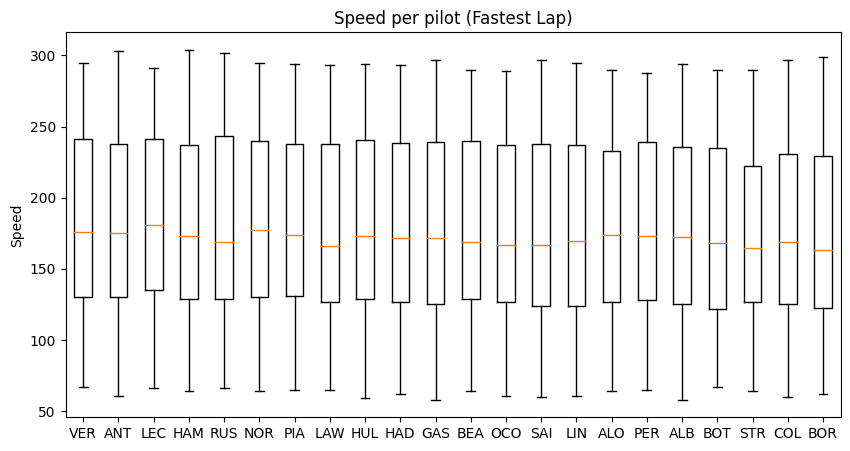

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([car_data[i]['Speed'].dropna() for i in drivers], labels=drivers)

ax.set_ylabel('Speed')
ax.set_title('Speed per pilot (Fastest Lap)')


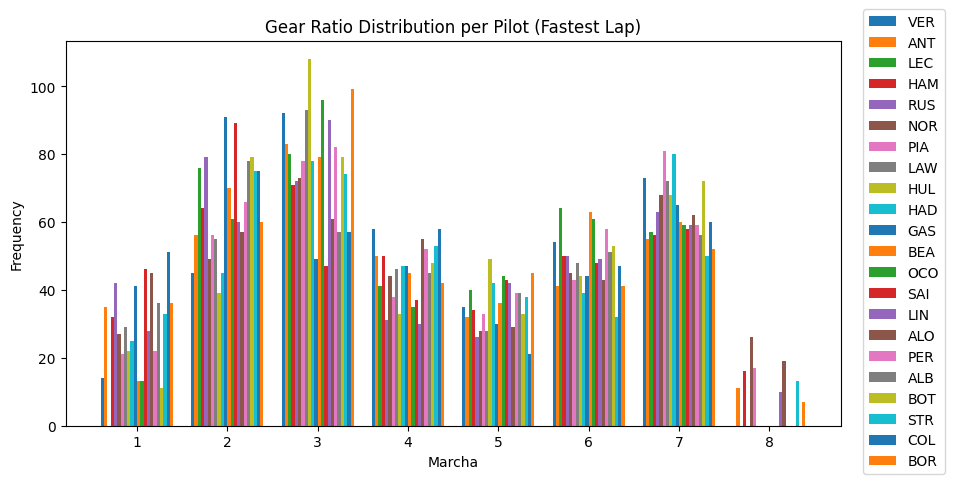

In [7]:
import numpy as np

bins = np.arange(0.5, 9.5, 1)   # 0.5, 1.5, ..., 8.5

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist([car_data[i]['nGear'].dropna() for i in drivers],
        bins=bins, label=drivers)

ax.set_xticks(range(1, 9))
ax.set_xlabel('Marcha')
ax.set_ylabel('Frequency')
ax.set_title('Gear Ratio Distribution per Pilot (Fastest Lap)')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.10))
plt.show()

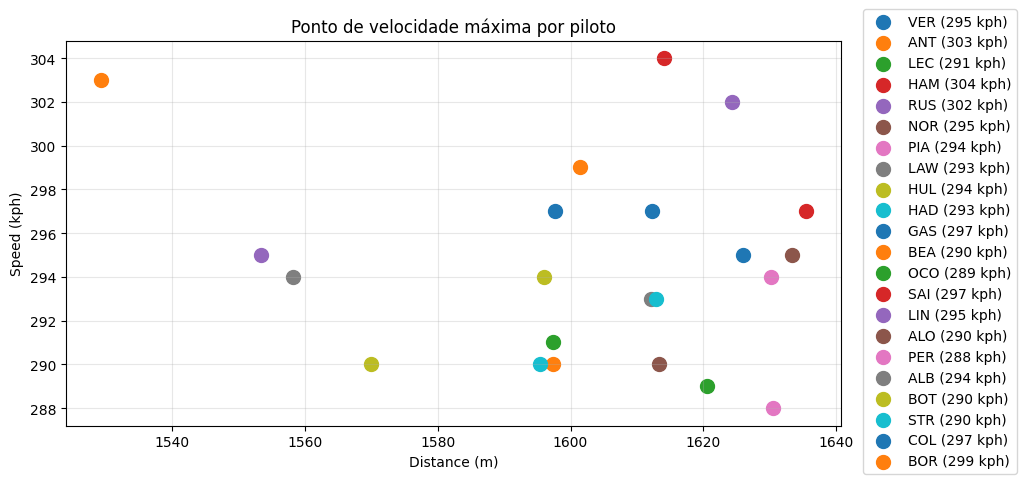

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

for i in drivers:
    d = car_data[i]
    idx = d['Speed'].idxmax()   # linha onde a velocidade é máxima
    ax.scatter(d.loc[idx, 'Distance'], d.loc[idx, 'Speed'],
               s=100, label=f"{i} ({d.loc[idx, 'Speed']:.0f} kph)")

ax.set_xlabel('Distance (m)')
ax.set_ylabel('Speed (kph)')
ax.set_title('Ponto de velocidade máxima por piloto')
ax.grid(alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.10))
plt.show()

C:\Users\Administrador\AppData\Local\Temp\ipykernel_26976\286885734.py:20: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations.
  plt.tight_layout()


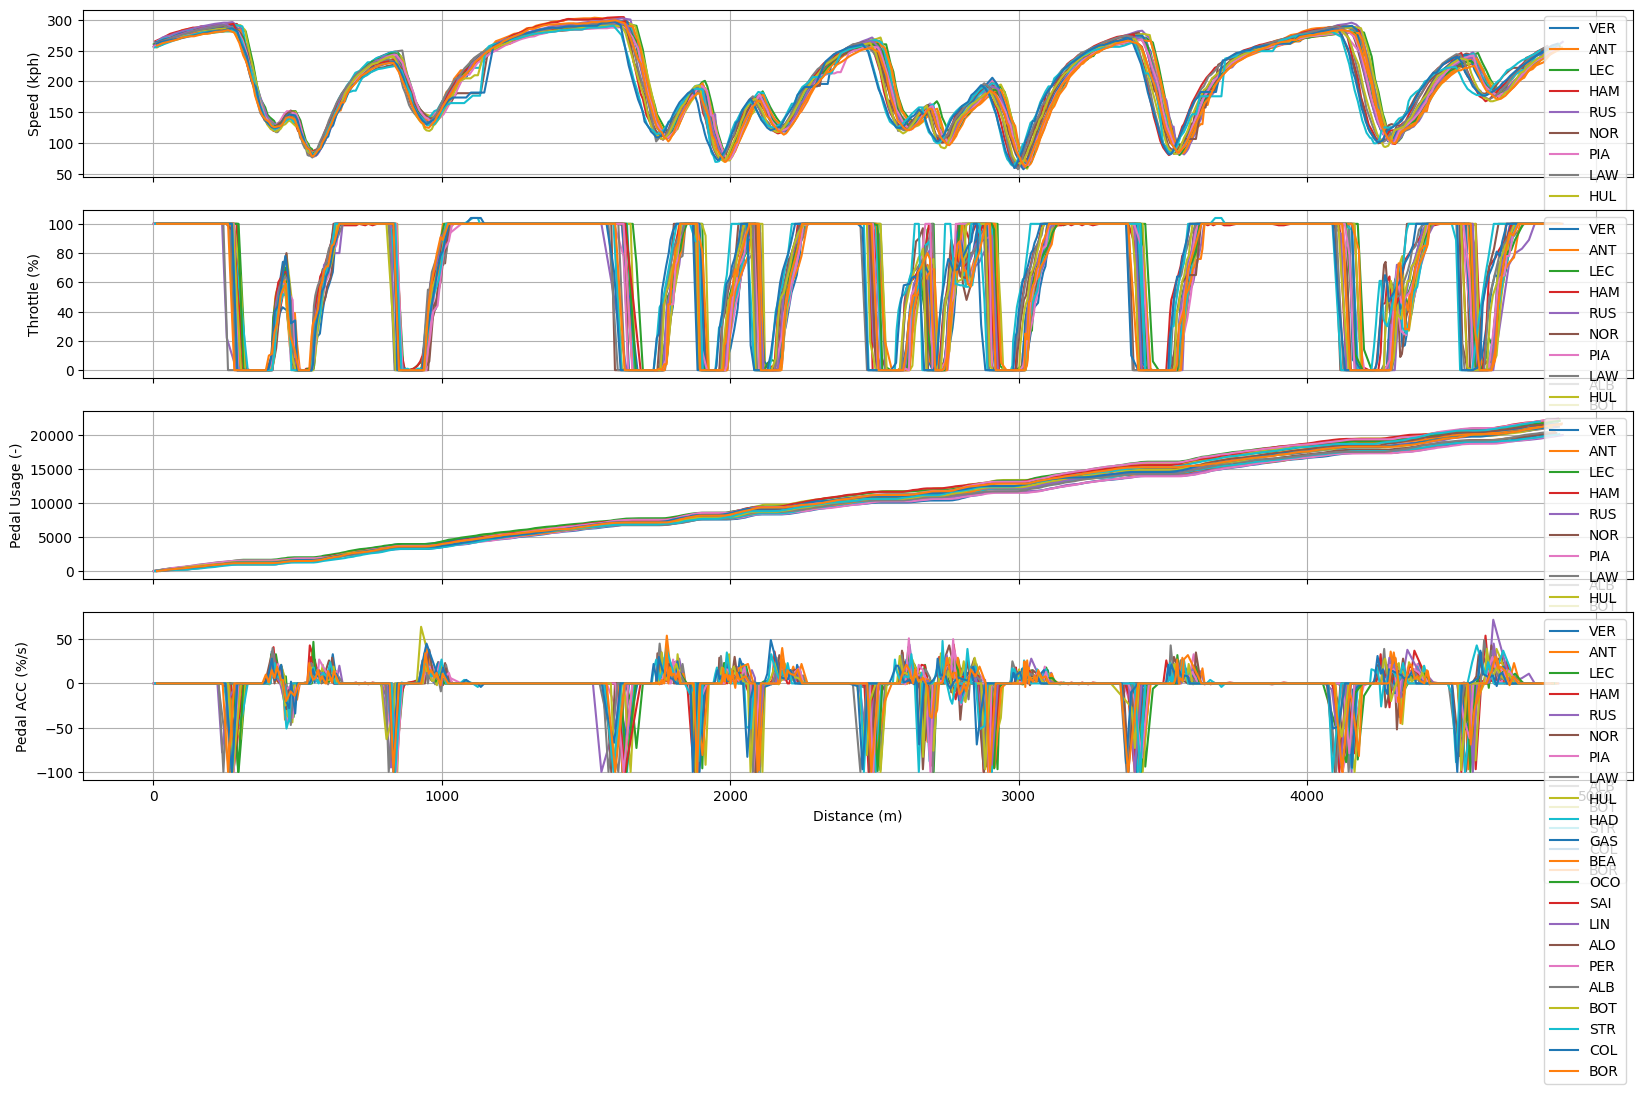

In [9]:
# (coluna, rótulo do eixo y)
channels = [
    ('Speed', 'Speed (kph)'),
    ('Throttle', 'Throttle (%)'),
    ('Pedal', 'Pedal Usage (-)'),
    ('Pedal_Acc', 'Pedal ACC (%/s)'),
]

fig1, axes = plt.subplots(4, figsize=(20, 10), sharex=True)

for ax, (col, ylabel) in zip(axes, channels):
    for i in drivers:
        ax.plot(car_data[i]['Distance'], car_data[i][col],
                label=i)
    ax.set_ylabel(ylabel)
    ax.grid()
    ax.legend()

axes[-1].set_xlabel('Distance (m)')
plt.tight_layout()
plt.show()


In [10]:
point_finishers = session_data.drivers[:10]
finishing_order = [session_data.get_driver(i)["Abbreviation"] for i in point_finishers]
driver_laps = {}

for i in finishing_order:
    driver_laps[i] = laps.pick_driver(i).pick_quicklaps()
    driver_laps[i] = driver_laps[i].reset_index()

all_driver_laps = pd.concat(driver_laps.values(), ignore_index=True)

In [11]:
finishing_order

['VER', 'LEC', 'HAM', 'ANT', 'NOR', 'PIA', 'GAS', 'LAW', 'LIN', 'HUL']

In [12]:
all_driver_laps.columns

Index(['index', 'Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber',
       'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time',
       'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime',
       'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST',
       'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team',
       'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted',
       'DeletedReason', 'FastF1Generated', 'IsAccurate'],
      dtype='object')

In [13]:
all_driver_laps['Sector1Time_s'] = all_driver_laps['Sector1Time'].dt.total_seconds()
all_driver_laps['Sector2Time_s'] = all_driver_laps['Sector2Time'].dt.total_seconds()
all_driver_laps['Sector3Time_s'] = all_driver_laps['Sector3Time'].dt.total_seconds()

In [14]:
all_driver_laps['Driver'].unique()

array(['VER', 'LEC', 'HAM', 'ANT', 'NOR', 'PIA', 'GAS', 'LAW', 'LIN',
       'HUL'], dtype=object)

Text(0.5, 1.0, 'Lap Time por piloto')

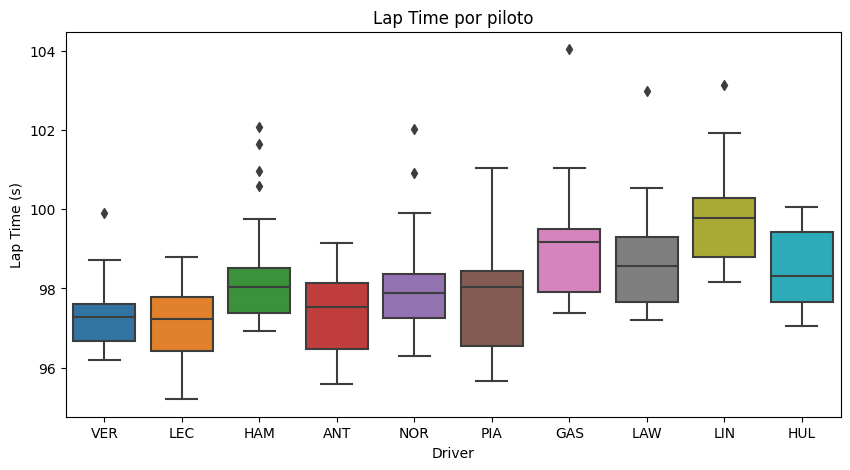

In [15]:
all_driver_laps['LapTime_s'] = all_driver_laps['LapTime'].dt.total_seconds()

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data = all_driver_laps, x='Driver', y='LapTime_s', ax=ax)

ax.set_ylabel('Lap Time (s)')
ax.set_xlabel('Driver')
ax.set_title('Lap Time por piloto')


###Observe os boxplots mais fechadinhos, isso significa que o piloto foi mais consistente, ou seja, teve menos variação de tempo entre as voltas.git

Text(0.5, 1.0, 'Sector 1 Time por piloto')

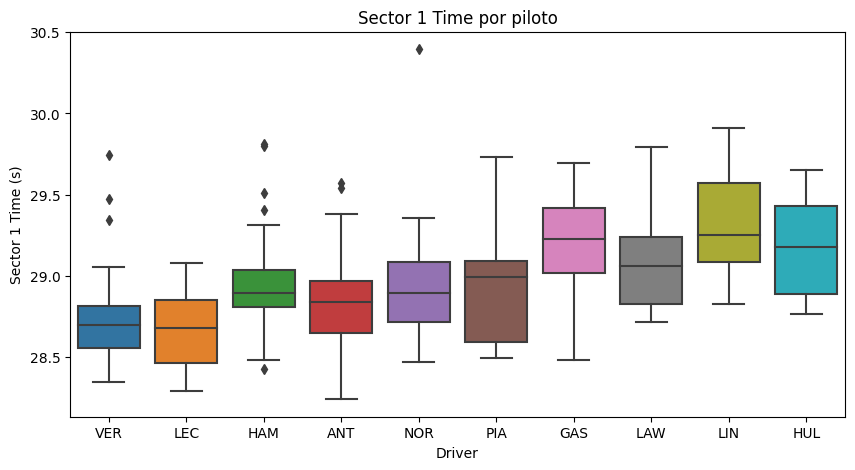

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data = all_driver_laps, x='Driver', y='Sector1Time_s', ax=ax)


ax.set_ylabel('Sector 1 Time (s)')
ax.set_xlabel('Driver')
ax.set_title('Sector 1 Time por piloto')

Text(0.5, 1.0, 'Sector 2 Time por piloto')

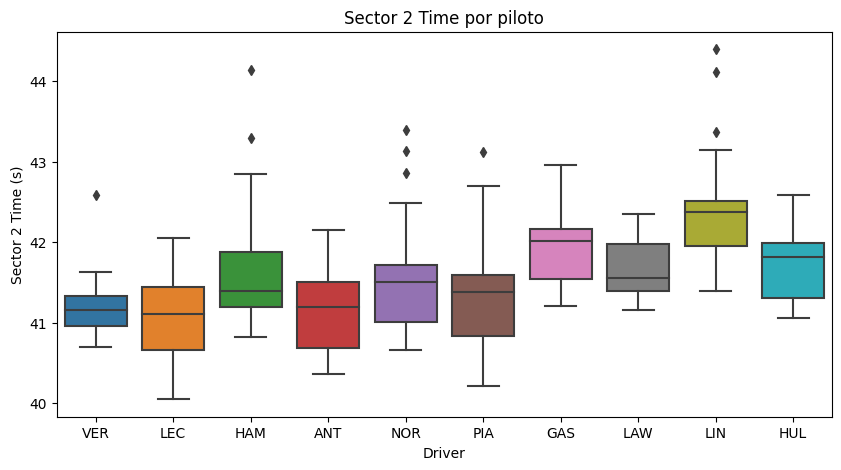

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data = all_driver_laps, x='Driver', y='Sector2Time_s', ax=ax)

ax.set_ylabel('Sector 2 Time (s)')
ax.set_xlabel('Driver')
ax.set_title('Sector 2 Time por piloto')

Text(0.5, 1.0, 'Sector 3 Time por piloto')

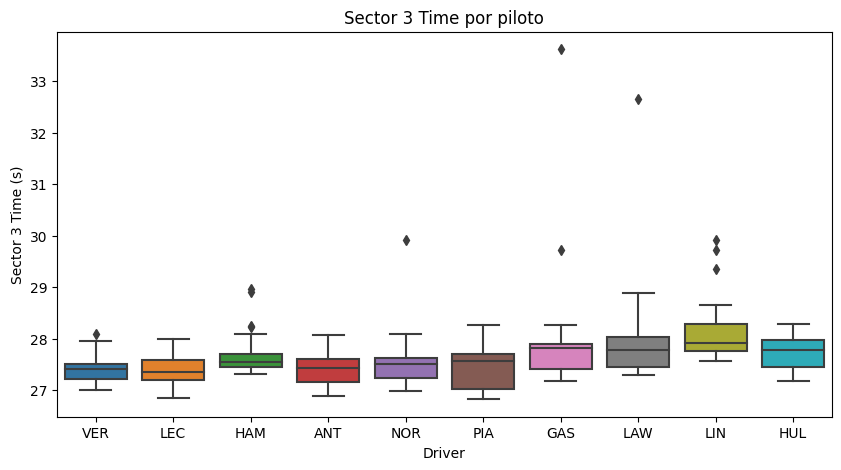

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data = all_driver_laps, x='Driver', y='Sector3Time_s', ax=ax)

ax.set_ylabel('Sector 3 Time (s)')
ax.set_xlabel('Driver')
ax.set_title('Sector 3 Time por piloto')

Text(0.5, 1.0, 'Lap Time por piloto')

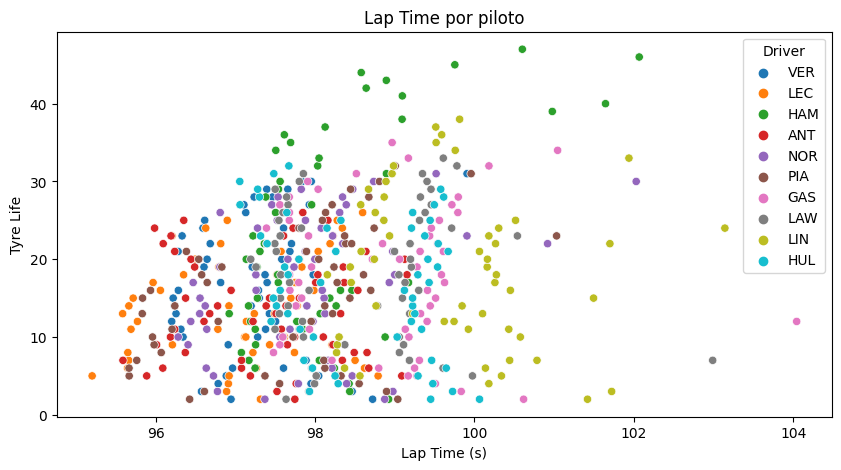

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data = all_driver_laps, y='TyreLife', x='LapTime_s', hue='Driver', ax=ax)

ax.set_xlabel('Lap Time (s)')
ax.set_ylabel('Tyre Life')
ax.set_title('Lap Time por piloto')

##Apesar de nos boxplots o HAM estar bem fechadinho o lap time dele piora com o desgaste dos pneus (bastante dispersão), ao contrario do VER que mantem uma baixa dispersão.
#Isto pode ser por conta do tipo de pneu ou pela configuração do carro, que pode ser mais sensível ao desgaste dos pneus.
#mas fica claro um bom gerenciamento de pneus do VER, onde percebe-se o desgaste bem concentrado.

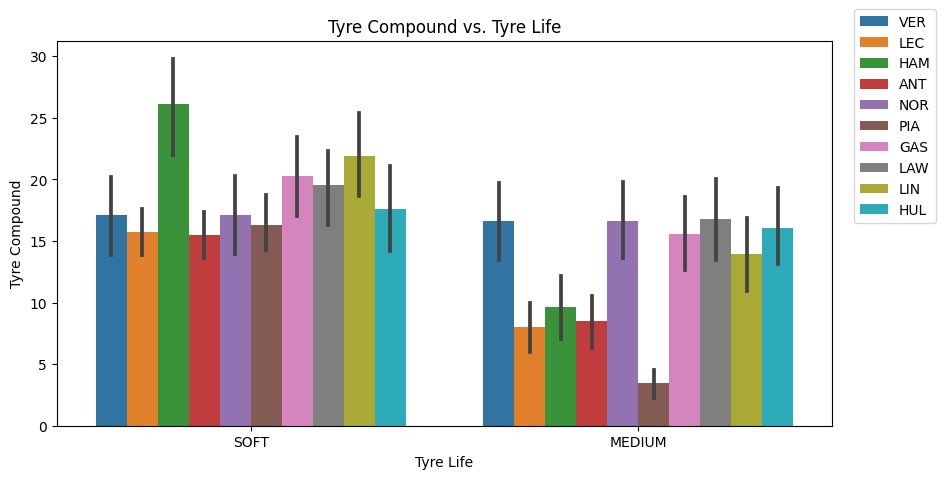

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data = all_driver_laps, y='TyreLife', x='Compound', hue='Driver', ax=ax)

ax.set_xlabel('Tyre Life')
ax.set_ylabel('Tyre Compound')
ax.set_title('Tyre Compound vs. Tyre Life')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.10))

#Percebe-se que a vida dos pneus do VER foi bem parecida para ambos os compostos

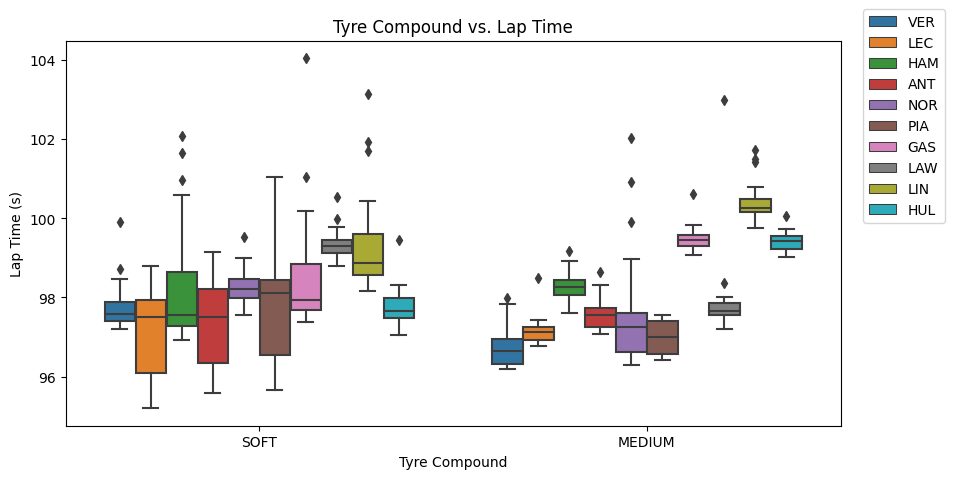

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data = all_driver_laps, y='LapTime_s', x='Compound', hue='Driver', ax=ax)

ax.set_xlabel('Tyre Compound')
ax.set_ylabel('Lap Time (s)')
ax.set_title('Tyre Compound vs. Lap Time')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.10))

Text(0.5, 1.0, 'Lap Time por piloto')

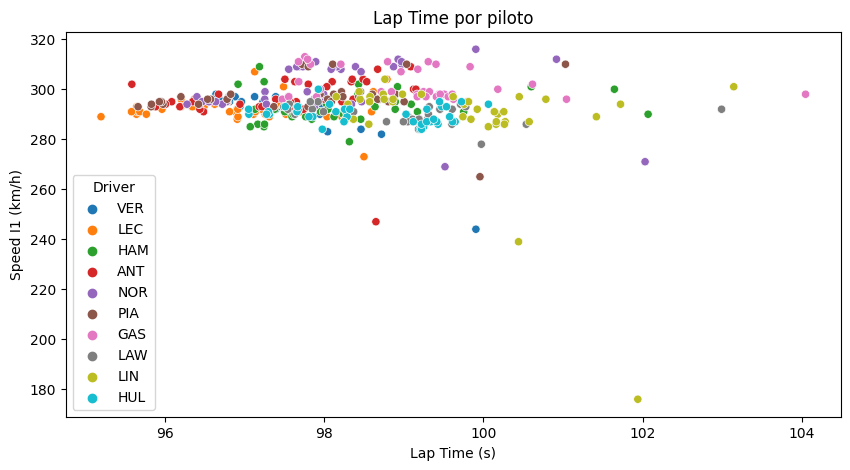

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data = all_driver_laps, y='SpeedI1', x='LapTime_s', hue='Driver', ax=ax)

ax.set_xlabel('Lap Time (s)')
ax.set_ylabel('Speed I1 (km/h)')
ax.set_title('Lap Time por piloto')

Text(0.5, 1.0, 'Lap Time por piloto')

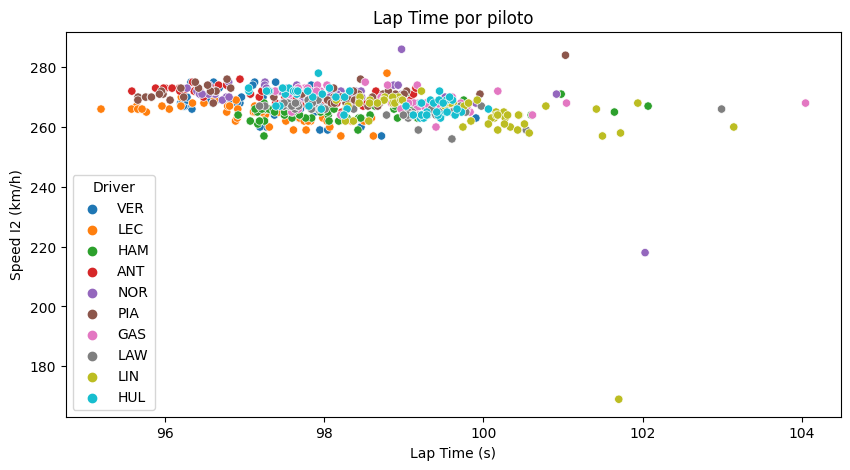

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data = all_driver_laps, y='SpeedI2', x='LapTime_s', hue='Driver', ax=ax)

ax.set_xlabel('Lap Time (s)')
ax.set_ylabel('Speed I2 (km/h)')
ax.set_title('Lap Time por piloto')

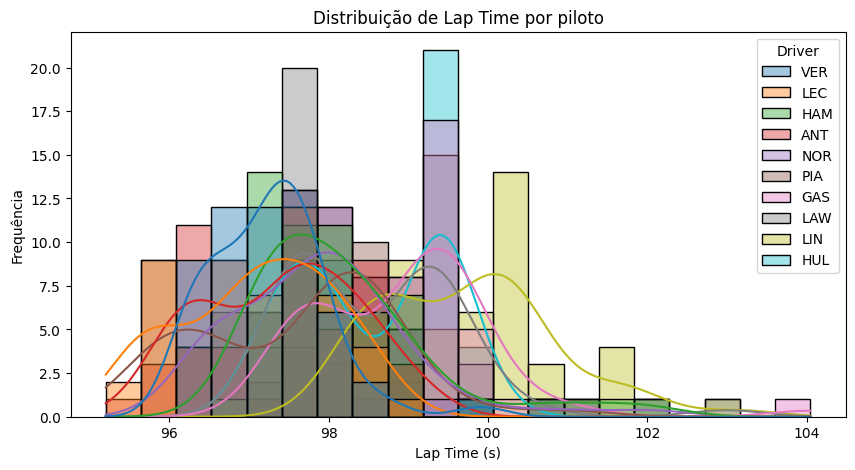

In [27]:
all_driver_laps['LapTime_s'] = all_driver_laps['LapTime'].dt.total_seconds()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=all_driver_laps, x='LapTime_s', hue='Driver',
             bins=20, kde=True, alpha=0.4, ax=ax)

ax.set_xlabel('Lap Time (s)')
ax.set_ylabel('Frequência')
ax.set_title('Distribuição de Lap Time por piloto')
plt.show()

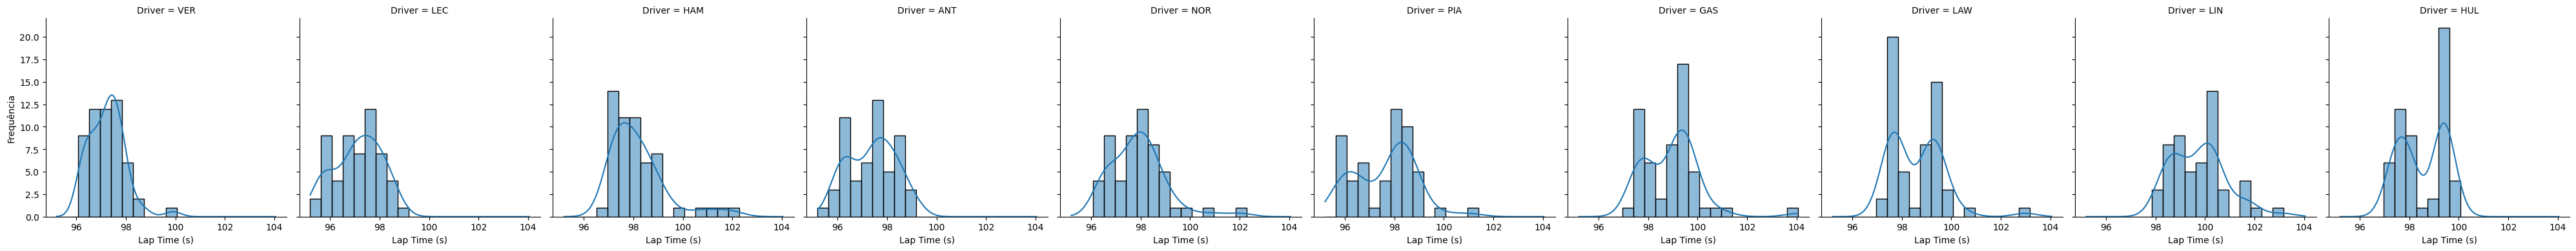

In [29]:
g = sns.displot(data=all_driver_laps, x='LapTime_s', col='Driver',
                bins=20, kde=True, height=4, aspect=1)
g.set_axis_labels('Lap Time (s)', 'Frequência')

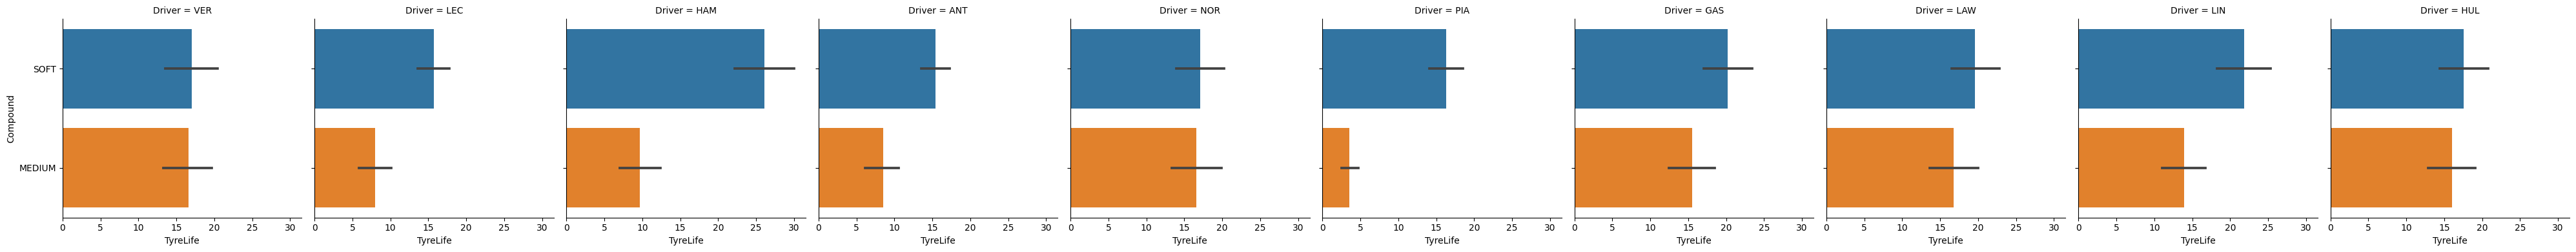

In [26]:
sns.catplot(data=all_driver_laps, x='TyreLife', y='Compound',
            col='Driver', kind='bar', orient='h', height=4, aspect=1)

In [41]:
ver_laps = all_driver_laps[all_driver_laps['Driver'] == 'VER']
LEC_laps = all_driver_laps[all_driver_laps['Driver'] == 'LEC']
HAM_laps = all_driver_laps[all_driver_laps['Driver'] == 'HAM']

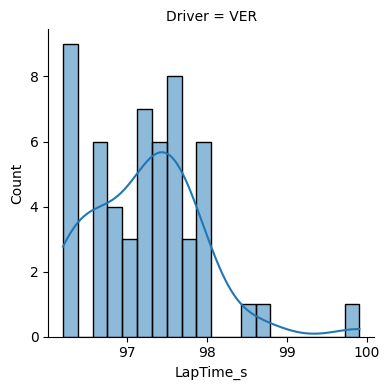

In [40]:
sns.displot( data = ver_laps, x='LapTime_s', col='Driver', bins=20, kde=True, height=4, aspect=1)


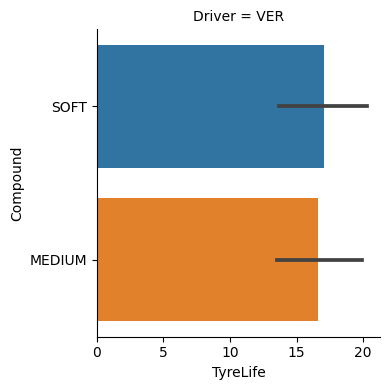

In [44]:
sns.catplot(data=ver_laps, x='TyreLife', y='Compound',
            col='Driver', kind='bar', orient='h', height=4, aspect=1)

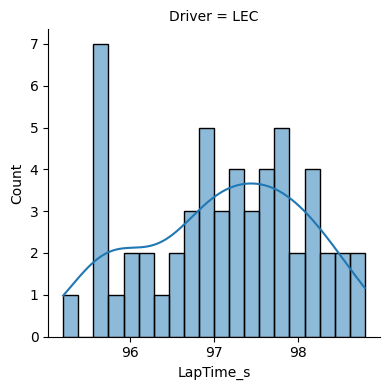

In [42]:
sns.displot( data = LEC_laps, x='LapTime_s', col='Driver', bins=20, kde=True, height=4, aspect=1)

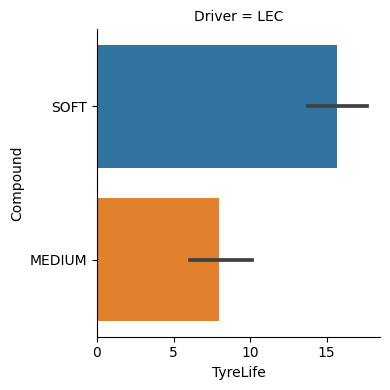

In [45]:
sns.catplot(data=LEC_laps, x='TyreLife', y='Compound',
            col='Driver', kind='bar', orient='h', height=4, aspect=1)

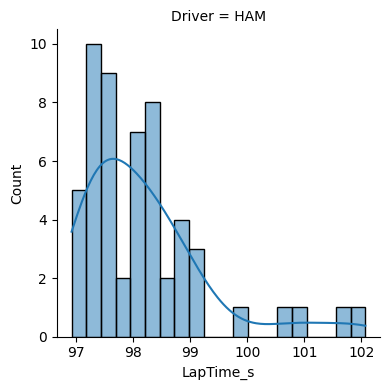

In [43]:
sns.displot( data = HAM_laps, x='LapTime_s', col='Driver', bins=20, kde=True, height=4, aspect=1)

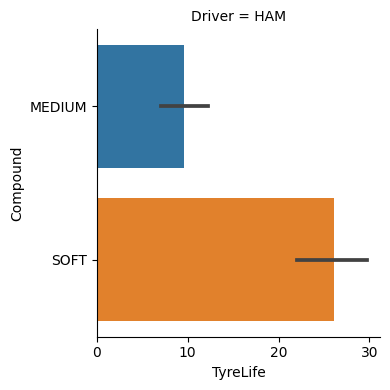

In [46]:
sns.catplot(data=HAM_laps, x='TyreLife', y='Compound',
            col='Driver', kind='bar', orient='h', height=4, aspect=1)